In [31]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [20]:
def mostrar(img, titulos, cmap='gray', tamanho=4):
  n = len(img)
  plt.figure(figsize=(tamanho*n, tamanho))
  for i in range(n):
    plt.subplot(1, n, i+1)
    plt.imshow(img[i], cmap=cmap)
    plt.title(titulos[i])
    plt.axis('off')
  plt.show()

In [8]:
gato = data.cat()
cafe = data.coffee()

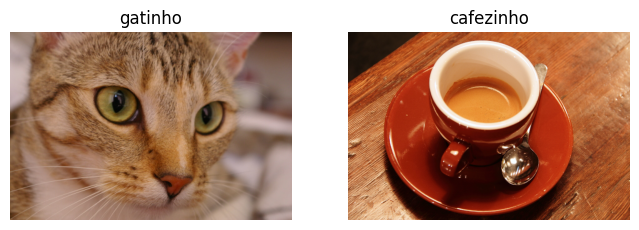

In [22]:
mostrar([gato, cafe], ['gatinho', 'cafezinho'])

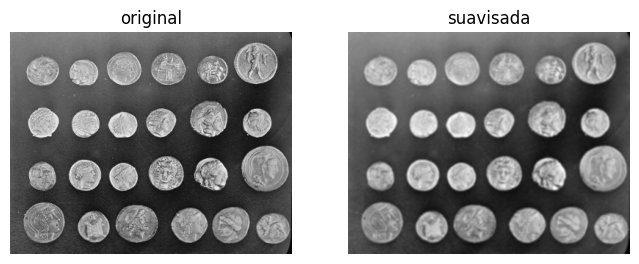

In [23]:
moedas = data.coins()
moedas_suave = cv2.GaussianBlur(moedas, (5, 5), 0)
mostrar([moedas, moedas_suave], ['original', 'suavisada'])

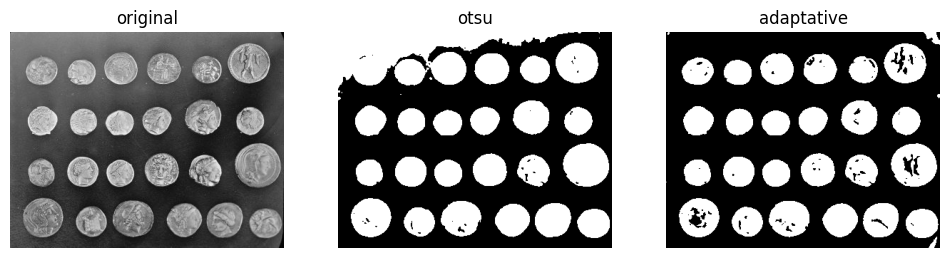

In [42]:
_, moedas_otsu = cv2.threshold(moedas_suave,
                             0,
                             255,
                             cv2.THRESH_OTSU)
moedas_adapt = cv2.adaptiveThreshold(moedas_suave,
                                   255,
                                   cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY,
                                   101,
                                   -10)

mostrar([moedas, moedas_otsu, moedas_adapt], ['original', 'otsu', 'adaptative'])

In [47]:
contornos, _ = cv2.findContours(moedas_adapt,
                              cv2.RETR_EXTERNAL,
                              cv2.CHAIN_APPROX_SIMPLE)
contornos = [c for c in contornos if cv2.contourArea(c) > 500]
print('Quantidade de contornos: ', len(contornos))

Quantidade de contornos:  24


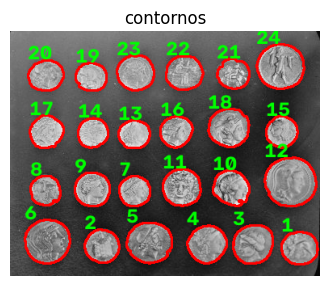

In [64]:
saida = cv2.cvtColor(moedas, cv2.COLOR_GRAY2RGB)
cv2.drawContours(saida, contornos, -1, (255, 0, 0), 2)

for i, c in enumerate(contornos):
  x, y, w, h = cv2.boundingRect(c)
  cv2.putText(saida, str(i+1), (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

mostrar([saida], ['contornos'])